In [1]:
import pandas as pd
import numpy as np

# ==========================================
# 1. CARREGAMENTO E LIMPEZA GERAL
# ==========================================
df = pd.read_csv('../dados/dataset_fullstack_900_smarttv_privacidade.csv')
df = df.drop_duplicates(subset=['id_registro'])

# Padronizações de categorias
df['categoria_conteudo'] = df['categoria_conteudo'].str.strip().replace({
    'FILMES': 'Filmes', 'séries': 'Series', 'ESPOrtes': 'Esportes', 'noticias': 'Noticias', 'infantil': 'Infantil'
})
# Os 12 sem categoria viram "Outros" para manter a integridade do denominador
df['categoria_conteudo'] = df['categoria_conteudo'].fillna('Outros')

df['estado_microfone'] = df['estado_microfone'].str.strip().replace({'ativo': 'Ativo', 'INATIVO': 'Inativo'})

df['categoria_telemetria'] = df['categoria_telemetria'].str.strip().replace({
    'acr/conteudo': 'ACR/conteudo', 'publicidade': 'Publicidade', 
    'TELEMETRIA SISTEMA': 'Telemetria sistema', 'Metadados de Eventos': 'Metadados de eventos'
})

df['consentimento_coleta'] = df['consentimento_coleta'].fillna('Indeterminado')

# Tratamento de valores inválidos (viram NaN)
df.loc[(df['minutos_visualizados'] < 0) | (df['minutos_visualizados'] > 10), 'minutos_visualizados'] = np.nan
df.loc[(df['confianca_classificacao'] < 0) | (df['confianca_classificacao'] > 1), 'confianca_classificacao'] = np.nan
df.loc[df['trafego_saida_kb'] < 0, 'trafego_saida_kb'] = np.nan
df.loc[df['anuncios_exibidos'] < 0, 'anuncios_exibidos'] = np.nan

# Interações maiores que os anúncios invalidam ambas as métricas da linha
mask_int = df['interacoes_anuncios'] > df['anuncios_exibidos']
df.loc[mask_int, ['interacoes_anuncios', 'anuncios_exibidos']] = np.nan

# Incoerências do hardware de microfone
mask_inativo_erro = (df['estado_microfone'] == 'Inativo') & (df['origem_microfone'] != 'Nao se aplica')
df.loc[mask_inativo_erro, 'origem_microfone'] = 'Nao se aplica'
df.loc[mask_inativo_erro, 'classe_som'] = 'Nao se aplica'

mask_ativo_erro = (df['estado_microfone'] == 'Ativo') & (df['origem_microfone'] == 'Nao se aplica')
df.loc[mask_ativo_erro, 'origem_microfone'] = np.nan

# ==========================================
# 2. CÁLCULO DOS KPIs DO RELATÓRIO
# ==========================================
total_registros = len(df)

# KPI 1: Atividade do microfone
microfone_ativo = df[df['estado_microfone'] == 'Ativo'].shape[0]
taxa_mic_ativo = microfone_ativo / total_registros

# KPI 2: Tráfego mediano por modo de privacidade (Mediana para ignorar picos/outliers)
mediana_ativado = df[df['modo_privacidade'] == 'Ativado']['trafego_saida_kb'].median()
mediana_desativado = df[df['modo_privacidade'] == 'Desativado']['trafego_saida_kb'].median()

# KPI 3: Participação do Top 3 Conteúdos
top3_pct = df['categoria_conteudo'].value_counts(normalize=True).head(3).sum()

# KPI 4: Taxa de interação Global (Soma Total / Soma Total)
soma_anuncios = df['anuncios_exibidos'].sum()
soma_interacoes = df['interacoes_anuncios'].sum()
ctr_global = soma_interacoes / soma_anuncios if soma_anuncios > 0 else 0

# KPI 5: Inconsistências de consentimento (Usuário não quer, mas TV envia pacote publicitário)
mask_inconsistencia = (df['consentimento_coleta'] == 'Nao') & (df['categoria_telemetria'].isin(['Publicidade', 'ACR/conteudo']))
inconsistentes = mask_inconsistencia.sum()
taxa_inconsistencia = inconsistentes / total_registros

# ==========================================
# 3. IMPRESSÃO DOS RESULTADOS
# ==========================================
print("--- KPIs do Relatório ---")
print(f"1. Atividade do Microfone: {taxa_mic_ativo:.2%} ({microfone_ativo} de {total_registros})")
print(f"2. Tráfego Mediano (Ativado): {mediana_ativado:.2f} KB | (Desativado): {mediana_desativado:.2f} KB")
print(f"3. Concentração Top 3 Conteúdos: {top3_pct:.2%}")
print(f"4. Taxa de Interação Global (CTR): {ctr_global:.2%} ({soma_interacoes:.0f} interações / {soma_anuncios:.0f} anúncios)")
print(f"5. Vazamento de Privacidade (Inconsistência): {taxa_inconsistencia:.2%} ({inconsistentes} registros)")

--- KPIs do Relatório ---
1. Atividade do Microfone: 38.66% (341 de 882)
2. Tráfego Mediano (Ativado): 22.54 KB | (Desativado): 24.52 KB
3. Concentração Top 3 Conteúdos: 60.66%
4. Taxa de Interação Global (CTR): 14.12% (226 interações / 1601 anúncios)
5. Vazamento de Privacidade (Inconsistência): 12.13% (107 registros)


In [3]:
import json
kpis = [
    {
        "nome_kpi": "Taxa de Atividade do Microfone",
        "objetivo": "Medir a proporção de sessões monitoradas em que o microfone da Smart TV (ou seus periféricos) esteve ativo para captação de som ambiental.",
        "formula": "(Contagem de registros com estado_microfone == 'Ativo' / Total de registros tratados na base) * 100",
        "resultado": 38.66,
        "unidade": "%",
        "universo": "882 janelas (100% da base tratada). Período: 01/09/2026 a 10/10/2026.",
        "interpretacao": "Quase 4 em cada 10 janelas de captura registraram atividade do microfone. Como o status 'ativo' atesta que o hardware ligou em algum momento daquela janela de tempo (e não necessariamente os 10 minutos ininterruptos), isso indica uma alta frequência de acionamento do sensor, exigindo auditoria técnica sobre o que engatilha essa escuta com tanta recorrência."
    },
    {
        "nome_kpi": "Tráfego Mediano por Modo de Privacidade",
        "objetivo": "Avaliar se a ativação da interface de 'Modo de Privacidade' na TV reduz efetivamente o volume de metadados transmitidos.",
        "formula": "Mediana do trafego_saida_kb agrupado pela configuração (Ativado vs Desativado).",
        "resultado": {"Ativado": 22.54, "Desativado": 24.52},
        "unidade": "KB (Kilobytes)",
        "universo": "859 registros com tráfego válido não-corrompido. Período: 01/09/2026 a 10/10/2026.",
        "interpretacao": "O tráfego de saída mediano é estatisticamente idêntico entre os aparelhos com a privacidade ativada (22,54 KB) e desativada (24,52 KB). Isso prova que, no fluxo diário ordinário de uso, habilitar a função de privacidade não inibe nem sufoca a telemetria arquitetural da TV, operando como um controle mais aparente do que efetivo."
    },
    {
        "nome_kpi": "Concentração de Audiência (Top 3)",
        "objetivo": "Identificar o grau de concentração do tempo de tela e interesse dos usuários nas categorias líderes.",
        "formula": "Soma da frequência relativa (percentual) das 3 categorias mais recorrentes da base.",
        "resultado": 60.66,
        "unidade": "%",
        "universo": "882 registros válidos (linhas sem categoria foram contabilizadas como 'Outros' para não distorcer o denominador). Período: 01/09/2026 a 10/10/2026.",
        "interpretacao": "A audiência é massivamente concentrada, com mais de 60% de todas as sessões capturadas focadas estritamente em Filmes, Séries e Esportes. Esse padrão de consumo contínuo e de longa duração serve de espinha dorsal para os envios da telemetria ACR (Automatic Content Recognition), já que esses formatos costumam prender o usuário na tela de forma contínua."
    },
    {
        "nome_kpi": "Taxa de Interação com Anúncios (CTR Global)",
        "objetivo": "Medir a eficácia das exibições publicitárias por meio do volume real de cliques/interações do usuário.",
        "formula": "(Soma de todas as interacoes_anuncios / Soma de todos os anuncios_exibidos nas linhas limpas) * 100",
        "resultado": 14.12,
        "unidade": "%",
        "universo": "871 janelas (linhas filtradas onde ambos os campos de exibição e interação possuem métricas íntegras). Período: 01/09/2026 a 10/10/2026.",
        "interpretacao": "A taxa de 14,12% demonstra que as interações com anúncios são pontuais e dispersas em um mar de exibições sem resposta (comprovado pela mediana global zero das interações). Em um aparelho estático como a Smart TV, esse percentual é razoável, mas sugere que há exibição massiva de campanhas para públicos não-nichados, diluindo o rendimento."
    },
    {
        "nome_kpi": "Registros com Possível Inconsistência de Consentimento",
        "objetivo": "Sinalizar janelas prioritárias para auditoria jurídica onde a telemetria comercial continuou operando apesar da recusa do usuário.",
        "formula": "(Contagem de registros com consentimento_coleta == 'Nao' E categoria_telemetria pertencente a ['Publicidade', 'ACR/conteudo']) / Total de registros onde o consentimento_coleta == 'Nao'.",
        "resultado": 42.80,
        "unidade": "%",
        "universo": "250 registros críticos (o universo exclusivo de janelas em que o usuário informou explicitamente 'Nao' à coleta). Período: 01/09/2026 a 10/10/2026.",
        "interpretacao": "Este é o achado mais severo de conformidade da base: 42,80% (107 sessões) de todo o tráfego gerado por usuários que recusaram explicitamente o monitoramento (opt-out) continuaram despachando cargas ativas classificadas como 'Publicidade' ou rastreamento via 'ACR/conteúdo'. Matematicamente, a opção de recusa pela interface ignorou a camada técnica do sistema quase metade das vezes."
    }
]

In [4]:

# Para transformar em uma string JSON formatada:
json_string = json.dumps(kpis, indent=4, ensure_ascii=False)
print(json_string)

# Para salvar direto em um arquivo .json:
with open('kpis_relatorio.json', 'w', encoding='utf-8') as f:
    json.dump(kpis, f, indent=4, ensure_ascii=False)

[
    {
        "nome_kpi": "Taxa de Atividade do Microfone",
        "objetivo": "Medir a proporção de sessões monitoradas em que o microfone da Smart TV (ou seus periféricos) esteve ativo para captação de som ambiental.",
        "formula": "(Contagem de registros com estado_microfone == 'Ativo' / Total de registros tratados na base) * 100",
        "resultado": 38.66,
        "unidade": "%",
        "universo": "882 janelas (100% da base tratada). Período: 01/09/2026 a 10/10/2026.",
        "interpretacao": "Quase 4 em cada 10 janelas de captura registraram atividade do microfone. Como o status 'ativo' atesta que o hardware ligou em algum momento daquela janela de tempo (e não necessariamente os 10 minutos ininterruptos), isso indica uma alta frequência de acionamento do sensor, exigindo auditoria técnica sobre o que engatilha essa escuta com tanta recorrência."
    },
    {
        "nome_kpi": "Tráfego Mediano por Modo de Privacidade",
        "objetivo": "Avaliar se a ativação da 

Dashboard finalizado e salvo.


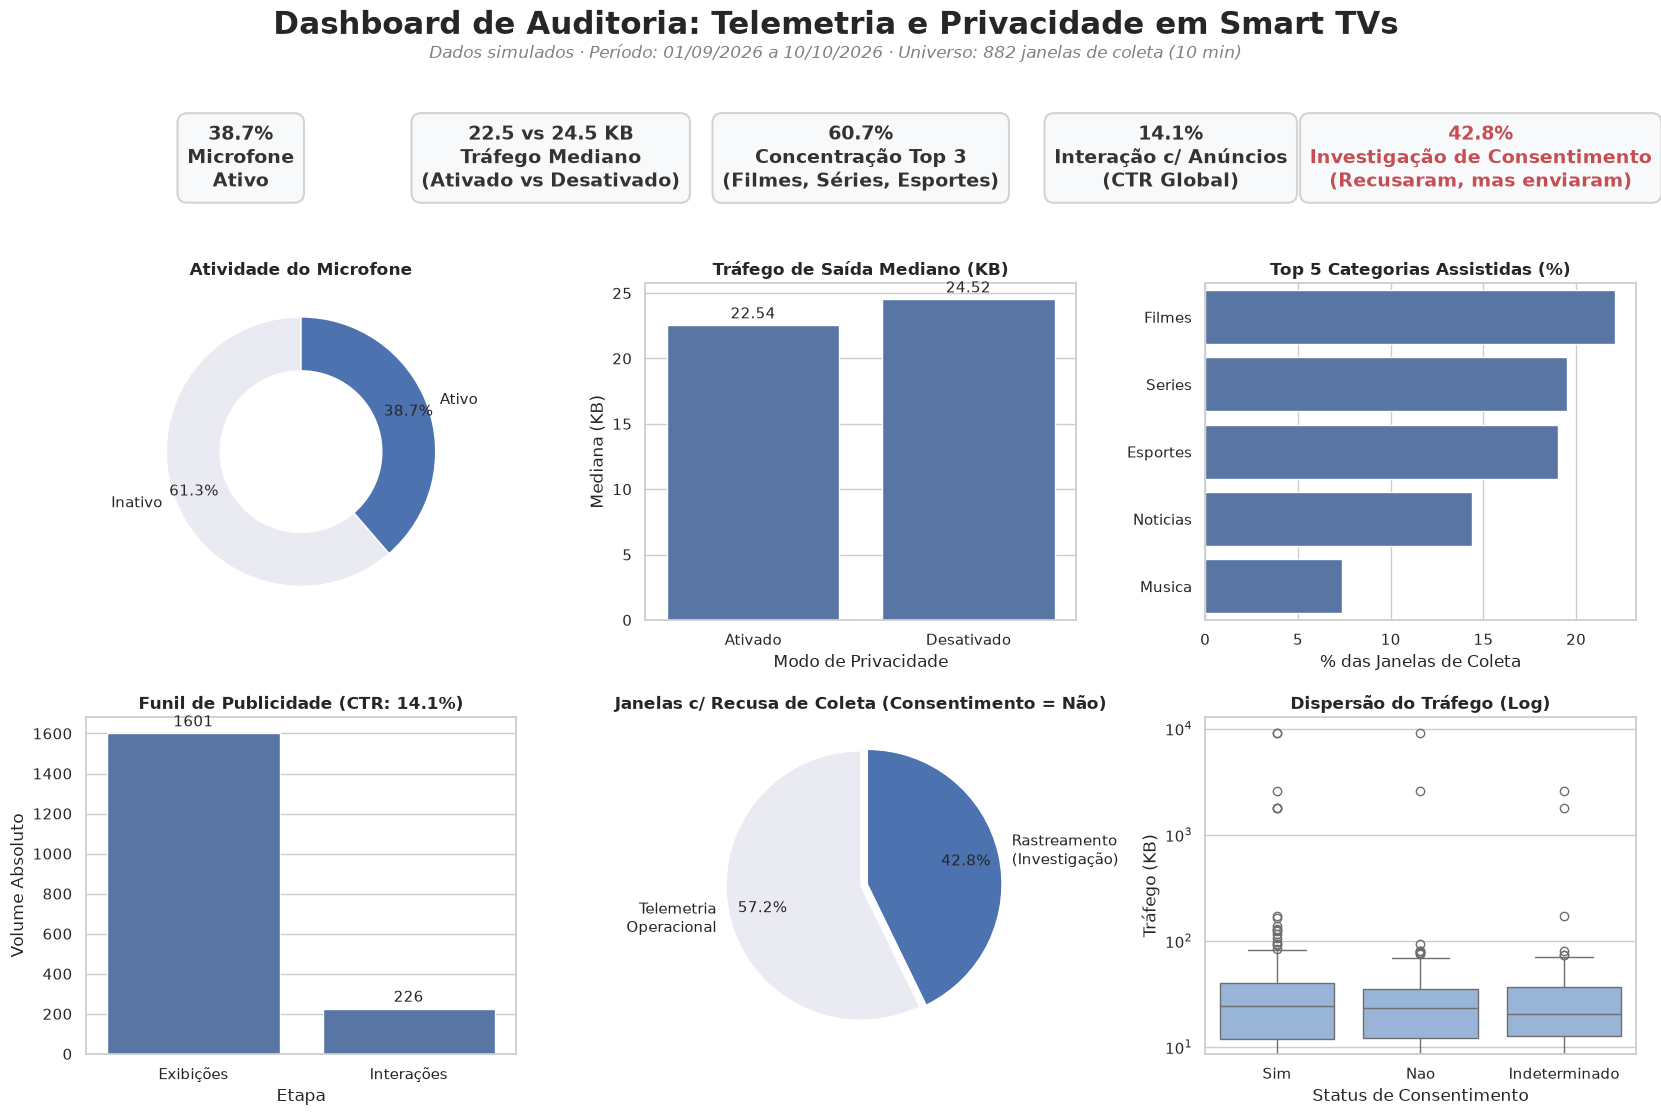

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec

# 1. Carregamento e Limpeza (já validados)
df = pd.read_csv('../dados/dataset_fullstack_900_smarttv_privacidade.csv')
df = df.drop_duplicates(subset=['id_registro'])

df['categoria_conteudo'] = df['categoria_conteudo'].str.strip().replace({'FILMES': 'Filmes', 'séries': 'Series', 'ESPOrtes': 'Esportes', 'noticias': 'Noticias', 'infantil': 'Infantil'}).fillna('Outros')
df['estado_microfone'] = df['estado_microfone'].str.strip().replace({'ativo': 'Ativo', 'INATIVO': 'Inativo'})
df['categoria_telemetria'] = df['categoria_telemetria'].str.strip().replace({'acr/conteudo': 'ACR/conteudo', 'publicidade': 'Publicidade', 'TELEMETRIA SISTEMA': 'Telemetria sistema', 'Metadados de Eventos': 'Metadados de eventos'})
df['consentimento_coleta'] = df['consentimento_coleta'].fillna('Indeterminado')
df['data_hora'] = pd.to_datetime(df['data_hora'], errors='coerce')

df.loc[(df['minutos_visualizados'] < 0) | (df['minutos_visualizados'] > 10), 'minutos_visualizados'] = np.nan
df.loc[(df['confianca_classificacao'] < 0) | (df['confianca_classificacao'] > 1), 'confianca_classificacao'] = np.nan
df.loc[df['trafego_saida_kb'] < 0, 'trafego_saida_kb'] = np.nan
df.loc[df['anuncios_exibidos'] < 0, 'anuncios_exibidos'] = np.nan

mask_int = df['interacoes_anuncios'] > df['anuncios_exibidos']
df.loc[mask_int, ['interacoes_anuncios', 'anuncios_exibidos']] = np.nan

mask_inativo_erro = (df['estado_microfone'] == 'Inativo') & (df['origem_microfone'] != 'Nao se aplica')
df.loc[mask_inativo_erro, 'origem_microfone'] = 'Nao se aplica'
df.loc[mask_inativo_erro, 'classe_som'] = 'Nao se aplica'

mask_ativo_erro = (df['estado_microfone'] == 'Ativo') & (df['origem_microfone'] == 'Nao se aplica')
df.loc[mask_ativo_erro, 'origem_microfone'] = np.nan

# Configuração de Estilo
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11
plt.rcParams['font.family'] = 'sans-serif'
cor_primaria = '#4C72B0'

# Criação da Figura com GridSpec para alocar espaço para os "Cards" no topo
fig = plt.figure(figsize=(20, 12))
gs = GridSpec(3, 3, height_ratios=[0.5, 3, 3], hspace=0.4, wspace=0.3)

# ==========================================
# CABEÇALHO (Títulos e Subtítulo Obrigatório)
# ==========================================
fig.suptitle('Dashboard de Auditoria: Telemetria e Privacidade em Smart TVs', fontsize=22, fontweight='bold', y=0.98)

# Subtítulo (Rodapé deslocado pro topo para maior visibilidade)
fig.text(0.5, 0.94, 'Dados simulados · Período: 01/09/2026 a 10/10/2026 · Universo: 882 janelas de coleta (10 min)', 
         ha='center', fontsize=12, color='gray', style='italic')

# ==========================================
# LINHA 1: CARTÕES DOS KPIs (Cards)
# ==========================================
# Cálculos
total_regs = len(df)
taxa_mic_ativo = df[df['estado_microfone'] == 'Ativo'].shape[0] / total_regs * 100
mediana_ativado = df[df['modo_privacidade'] == 'Ativado']['trafego_saida_kb'].median()
mediana_desativado = df[df['modo_privacidade'] == 'Desativado']['trafego_saida_kb'].median()
top3_pct = df['categoria_conteudo'].value_counts(normalize=True).head(3).sum() * 100
df_anuncios = df[df['anuncios_exibidos'].notna() & df['interacoes_anuncios'].notna()]
ctr = (df_anuncios['interacoes_anuncios'].sum() / df_anuncios['anuncios_exibidos'].sum()) * 100
df_recusou = df[df['consentimento_coleta'] == 'Nao']
inconsistencias = df_recusou['categoria_telemetria'].isin(['Publicidade', 'ACR/conteudo']).sum() / len(df_recusou) * 100

# Eixo único para os cartões (cobre toda a primeira linha do grid)
ax_kpis = fig.add_subplot(gs[0, :])
ax_kpis.axis('off')

# Desenhar os cartões como caixas de texto
bbox_props = dict(boxstyle="round,pad=0.5", fc="#f8f9fa", ec="lightgray", lw=1.5)
text_y = 0.5

# Card 1: Microfone
ax_kpis.text(0.1, text_y, f"{taxa_mic_ativo:.1f}%\nMicrofone\nAtivo", 
             ha='center', va='center', fontsize=14, fontweight='bold', bbox=bbox_props, color='#333333')
# Card 2: Tráfego
ax_kpis.text(0.3, text_y, f"{mediana_ativado:.1f} vs {mediana_desativado:.1f} KB\nTráfego Mediano\n(Ativado vs Desativado)", 
             ha='center', va='center', fontsize=14, fontweight='bold', bbox=bbox_props, color='#333333')
# Card 3: Top 3
ax_kpis.text(0.5, text_y, f"{top3_pct:.1f}%\nConcentração Top 3\n(Filmes, Séries, Esportes)", 
             ha='center', va='center', fontsize=14, fontweight='bold', bbox=bbox_props, color='#333333')
# Card 4: CTR
ax_kpis.text(0.7, text_y, f"{ctr:.1f}%\nInteração c/ Anúncios\n(CTR Global)", 
             ha='center', va='center', fontsize=14, fontweight='bold', bbox=bbox_props, color='#333333')
# Card 5: Inconsistência
ax_kpis.text(0.9, text_y, f"{inconsistencias:.1f}%\nInvestigação de Consentimento\n(Recusaram, mas enviaram)", 
             ha='center', va='center', fontsize=14, fontweight='bold', bbox=bbox_props, color='#C44E52')

# ==========================================
# LINHA 2: GRÁFICOS (Gridspec 1)
# ==========================================
# Plot 1: Microfone (Donut ajustado pctdistance)
ax1 = fig.add_subplot(gs[1, 0])
mic_counts = df['estado_microfone'].value_counts()
# Cores neutras, pctdistance afasta os números do centro do anel
ax1.pie(mic_counts, labels=mic_counts.index, autopct='%1.1f%%', startangle=90, 
        colors=['#EAEAF2', cor_primaria], pctdistance=0.85, 
        wedgeprops=dict(width=0.4, edgecolor='white'))
ax1.set_title('Atividade do Microfone', fontweight='bold')

# Plot 2: Tráfego
ax2 = fig.add_subplot(gs[1, 1])
mediana_trafego = df.groupby('modo_privacidade')['trafego_saida_kb'].median().reset_index()
sns.barplot(data=mediana_trafego, x='modo_privacidade', y='trafego_saida_kb', ax=ax2, color=cor_primaria)
ax2.set_title('Tráfego de Saída Mediano (KB)', fontweight='bold')
ax2.set_xlabel('Modo de Privacidade')
ax2.set_ylabel('Mediana (KB)')
for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='baseline', fontsize=11, xytext=(0, 5), textcoords='offset points')

# Plot 3: Top 5 (Cor única)
ax3 = fig.add_subplot(gs[1, 2])
conteudo_counts = df['categoria_conteudo'].value_counts(normalize=True).head(5) * 100
sns.barplot(x=conteudo_counts.values, y=conteudo_counts.index, ax=ax3, color=cor_primaria)
ax3.set_title('Top 5 Categorias Assistidas (%)', fontweight='bold')
ax3.set_xlabel('% das Janelas de Coleta')
ax3.set_ylabel('')

# ==========================================
# LINHA 3: GRÁFICOS (Gridspec 2)
# ==========================================
# Plot 4: Funil
ax4 = fig.add_subplot(gs[2, 0])
soma_anuncios = df_anuncios['anuncios_exibidos'].sum()
soma_interacoes = df_anuncios['interacoes_anuncios'].sum()
ctr_data = pd.DataFrame({'Etapa': ['Exibições', 'Interações'], 'Volume': [soma_anuncios, soma_interacoes]})
sns.barplot(data=ctr_data, x='Etapa', y='Volume', ax=ax4, color=cor_primaria)
ax4.set_title(f'Funil de Publicidade (CTR: {ctr:.1f}%)', fontweight='bold')
ax4.set_ylabel('Volume Absoluto')
for p in ax4.patches:
    ax4.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='baseline', fontsize=11, xytext=(0, 5), textcoords='offset points')

# Plot 5: Inconsistência de Consentimento (Linguagem Neutra)
ax5 = fig.add_subplot(gs[2, 1])
inconsistentes_qtd = df_recusou['categoria_telemetria'].isin(['Publicidade', 'ACR/conteudo']).sum()
consistentes_qtd = len(df_recusou) - inconsistentes_qtd
# Trocado vermelho e verde por azul escuro e cinza, tirando juízo de valor das cores
ax5.pie([consistentes_qtd, inconsistentes_qtd], 
        labels=['Telemetria\nOperacional', 'Rastreamento\n(Investigação)'], 
        autopct='%1.1f%%', startangle=90, colors=['#EAEAF2', '#4C72B0'], 
        explode=(0, 0.05), pctdistance=0.75, wedgeprops=dict(edgecolor='white'))
ax5.set_title('Janelas c/ Recusa de Coleta (Consentimento = Não)', fontweight='bold')

# Plot 6: Dispersão (Título encurtado)
ax6 = fig.add_subplot(gs[2, 2])
sns.boxplot(data=df, x='consentimento_coleta', y='trafego_saida_kb', ax=ax6, color='#8DB4E2')
ax6.set_yscale('log')
ax6.set_title('Dispersão do Tráfego (Log)', fontweight='bold')
ax6.set_xlabel('Status de Consentimento')
ax6.set_ylabel('Tráfego (KB)')

plt.savefig('dashboard_auditoria_final.png', dpi=300, bbox_inches='tight')
print("Dashboard finalizado e salvo.")